# Part 7: Regression Problems and Remedies {-}

In [1]:
import warnings
warnings.filterwarnings(action='ignore')

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

This Part will cover some common challenges encountered when fitting regression models, along with some potential ways to address these problems.

We will make use of the same Fama-French three-factor example that was introduced in Part 4. Recall that the output of the model was stored in `ff3modPNC`. (The code is included in the Python notebook.)

In [2]:
def getFamaFrench(from_date, to_date):
    
    import pandas_datareader.data as web    
    from datetime import datetime
    
    df = web.DataReader("F-F_Research_Data_Factors_daily", "famafrench")[0]
    
    df.columns=['MktRF','SMB','HML','RF']

    return df[(df.index >= from_date) & (df.index <= to_date)]

ffhold = getFamaFrench(from_date="2024-1-1", to_date="2024-6-30")
PNCohlc = yf.Ticker("PNC").history(start="2024-01-01", end="2024-06-30")
PNCret = PNCohlc['Close'].pct_change().dropna()

ffhold = ffhold[1:]
ffhold['PNCexret'] = 100*np.array(PNCret) - ffhold['RF']

ff3modPNC = sm.OLS.from_formula(formula="PNCexret ~ MktRF + SMB + HML", data=ffhold).fit()

\newpage

## Robust Regression {-}

In the least squares approach to estimation in regression, we seek the
$\boldsymbol{\beta}$ that minimizes the residual sum of squares
\begin{equation*}
   \sum_{i=1}^n \left(y_i - {\bf x}_i^T\!\boldsymbol{\beta}\right)^2.
\end{equation*}

This is equivalent to minimizing
\begin{equation*}
   \frac{1}{\sigma^2} \sum_{i=1}^n \left(y_i - {\bf x}_i^T\!\boldsymbol{\beta}\right)^2
   =
   \sum_{i=1}^n \left(\frac{y_i - {\bf x}_i^T\!\boldsymbol{\beta}}{\sigma}\right)^{\!2}
   = 
   \sum_{i=1}^n \rho\!\left(\frac{y_i - {\bf x}_i^T\!\boldsymbol{\beta}}{\sigma}\right)
\end{equation*}
where $\rho(x) = x^2$.

The general concern with $\rho(x) = x^2$ is that it may place too much weight
on extreme observations: Think about how quickly the function $x^2$ increases
as $|x|$ increases.

The choice $\rho(x) = x^2$ may be optimal when the errors are normal, but
it is not very **robust** to deviations from this assumption.

If we generated errors from the $t$ distribution with four degrees of freedom,
for instance, we are likely to see a few extreme errors. These observations
would have a large influence on the fit of the model, if we proceeded with
$\rho(x) = x^2$.

\newpage

There are many possible choices for $\rho$, but here we will focus on
a popular one, the **Huber loss function**, which is defined as
\begin{equation*}
   \rho_{\mbox{\tiny Hub}}(x) = \left\{
   \begin{array}{ll}
   x^2 & \mbox{if $|x| < k$} \\
   k(2|x| -k) & \mbox{otherwise} \\
   \end{array}
   \right.
\end{equation*}
where $k >0$ is set by the user. For technical reasons, the
default choice is $k = 1.345$.

The figure below compares squared error loss with the Huber
loss function.

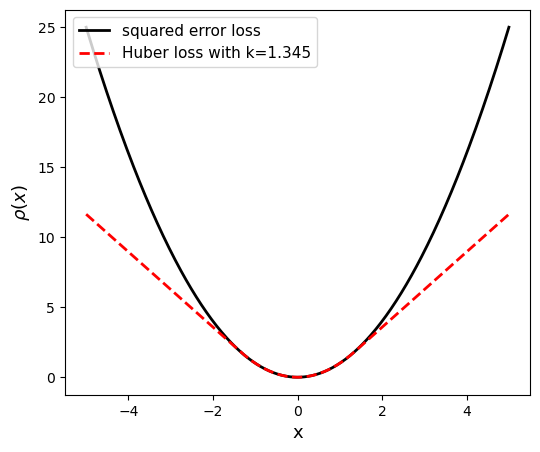

In [3]:
def rho_huber(x, c=1.345):
    x = np.asarray(x)
    out = np.zeros_like(x, dtype=float)
    
    # Absolute value condition
    foo = np.abs(x) < c
    
    # Apply conditions
    out[foo] = x[foo]**2
    out[~foo] = c * (2 * np.abs(x[~foo]) - c)
    return out

# Generate x values for the curve
x_vals = np.linspace(-5, 5, 500)
y_squared = x_vals**2
y_huber = rho_huber(x_vals)

# Create the plot
plt.figure(figsize=(6, 5))
plt.plot(x_vals, y_squared, color='black', linewidth=2, linestyle='-', label="squared error loss")
plt.plot(x_vals, y_huber, color='red', linewidth=2, linestyle='--', label="Huber loss with k=1.345")

plt.xlabel("x", fontsize=13)
plt.ylabel(r"$\rho(x)$", fontsize=13)
plt.legend(loc="upper left", fontsize=11)

plt.show()

\newpage

**Exercise:** What is the effect of varying $k$ in
the Huber loss function?

\answerlines{18}

\newpage

**Example:** In this example the truth is that $\beta_0 = 1$ and $\beta_1 = 10$.
The sample size is $n=100$. The error has the $t$ distribution with
a single degree of freedom, so there is great potential for extreme
observations.

The figure above shows two simulated
data sets under these conditions, each with the true line (solid),
the regression line estimated using least squares (dashed), and
the regression line estimated using the Huber loss (dashed-dot).

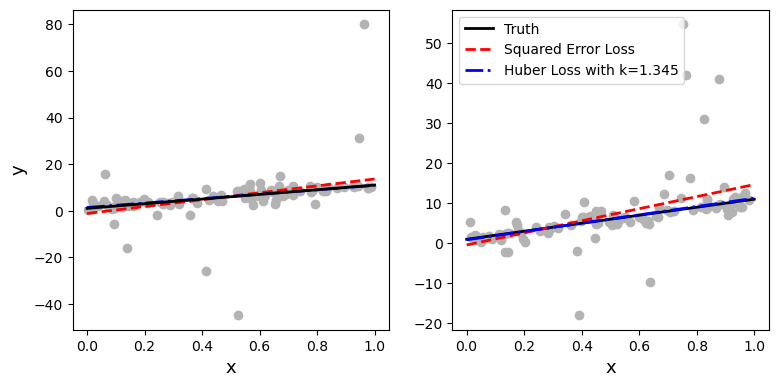

In [4]:
n = 100
df = 1
beta0 = 1
beta1 = 10

# Create a figure for the side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
fig.subplots_adjust(left=0.08, right=0.95, bottom=0.15, top=0.95)

# For drawing the regression lines (x ranges from roughly 0 to 1)
x_line = np.array([0, 1])

np.random.seed(0)

x1 = np.random.uniform(size=n)
# rt(n, df) equivalent is np.random.standard_t
y1 = beta0 + beta1 * x1 + np.random.standard_t(df, size=n) 

# Add constant for statsmodels (equivalent to the intercept in R's formula y~x)
X1 = sm.add_constant(x1)

# Fit OLS (equivalent to default glm) and RLM (Robust Linear Model)
holdlm1 = sm.OLS(y1, X1).fit()
holdrlm1 = sm.RLM(y1, X1, M=sm.robust.norms.HuberT(t=1.345)).fit()

# Plot first simulation
axes[0].scatter(x1, y1, color=(0.7, 0.7, 0.7), marker='o')
axes[0].plot(x_line, holdlm1.params[0] + holdlm1.params[1] * x_line, color='red', linewidth=2, linestyle='--')
axes[0].plot(x_line, holdrlm1.params[0] + holdrlm1.params[1] * x_line, color='blue', linewidth=2, linestyle='-.')
axes[0].plot(x_line, beta0 + beta1 * x_line, color='black', linewidth=2, linestyle='-')
axes[0].set_xlabel("x", fontsize=13)
axes[0].set_ylabel("y", fontsize=13)


np.random.seed(40)

x2 = np.random.uniform(size=n)
y2 = beta0 + beta1 * x2 + np.random.standard_t(df, size=n)

X2 = sm.add_constant(x2)

holdlm2 = sm.OLS(y2, X2).fit()
holdrlm2 = sm.RLM(y2, X2, M=sm.robust.norms.HuberT(t=1.345)).fit()

# Plot second simulation
axes[1].scatter(x2, y2, color=(0.7, 0.7, 0.7), marker='o')

# Plot lines and add labels for the legend
axes[1].plot(x_line, beta0 + beta1 * x_line, color='black', linewidth=2, linestyle='-', label="Truth")
axes[1].plot(x_line, holdlm2.params[0] + holdlm2.params[1] * x_line, color='red', linewidth=2, linestyle='--', label="Squared Error Loss")
axes[1].plot(x_line, holdrlm2.params[0] + holdrlm2.params[1] * x_line, color='blue', linewidth=2, linestyle='-.', label="Huber Loss with k=1.345")
axes[1].set_xlabel("x", fontsize=13)
#axes[1].set_ylabel("y", fontsize=13)

# Add legend to the second plot
axes[1].legend(loc="upper left")

plt.show()

It is clear that in both instances that the Huber loss function
effectively downweights the extreme observations, and, as a result,
results in a closer approximation to the truth.

These examples are, admittedly, chosen to be extreme to illustrate
the point. Nevertheless, robust regression is useful in situations
where it is suspected that the error distribution is not normal,
and there is concern over extreme observations.

\newpage

Robust regression is implemented using `RLM` from
`statsmodels`.

The argument `M` sets the loss function.
The default setting is `M=sm.robust.norms.HuberT`,
which uses the Huber loss function
with $k=1.345$.

In [5]:
ff3modPNCrob = sm.RLM.from_formula(formula="PNCexret ~ MktRF + SMB + HML", data=ffhold).fit()

**Exercise:** Compare the results of this fit with least squares. Has much changed?

\answerlines{10}

\newpage

## Multicollinearity {-}

As the number of predictors increases, there is a greater
risk of **multicollinearity**, a condition in which
two or more predictors are strongly linearly related to one another.

It is useful to consider two different "levels" of multicollinearity, as
different references seem to attach a different meaning to the term.

In the extreme version of multicollinearity, there is such a strong correlation
among the predictors that there are numerical problems in deriving the least
squares estimators. You may recall that finding the $\widehat \beta_i$ and
their standard errors
involves inverting the matrix ${\bf X}^T{\bf X}$. The inverse will be undefined
or numerically unstable if the correlations are sufficiently strong.

In the less extreme version, the correlation between the predictors makes it
difficult to distinguish the individual contributions of predictors to the
response. This is the more typical situation that one would encounter in
practice. In fact, predictors are almost always somewhat correlated.

\newpage

**Exercise:** Why might one be interested in attributing the individual contributions of predictors to the response?

\answerlines{18}

\newpage

The following diagnostic is useful in this regard.

As before, suppose that there are $p$ predictors in the model. In order to quantify
the relationship between $x_k$ and the other $p-1$ predictors, we fit
a linear regression model with $x_k$ as the response and the other variables
as the predictors:
\begin{equation*}
   x_k = \beta_0 + \sum_{j \neq k} \beta_j x_j + \epsilon
\end{equation*}
If $x_k$ can be well-predicted by the other variables, then we have
multicollinearity. 

Note that multicollinearity does not require $x_k$ to be related to
any one of the other predictors, but merely related to a *linear combination*
of the other predictors.

Suppose this regression is fit, and the coefficient of determination
is obtained, call it $R^2_k$. It directly follows that $R^2_k$
close to one is a sign of multicollinearity.

\newpage

We define the **variance inflation factor** for the $k^{th}$ predictor to be
\begin{equation*}
   {\rm VIF}_k = \frac{1}{1-R^2_k}.
\end{equation*}

A large VIF is a sign of multicollinearity.

Where does the name come from?
In the case of OLS, it can be shown that
\begin{eqnarray*}
   V(\widehat \beta_k) & = & 
   \frac{1}{1-R^2_k} \times \frac{\sigma^2}{(n-1)s^2_{x_k}} \\ 
 && \\
   & = & 
   {\rm VIF}_k \times \left(\mbox{$V(\widehat \beta_k)$ if $x_k$ was only predictor in model}\right) \\
\end{eqnarray*}
So, ${\rm VIF}_k$ is the amount by which the variance of the estimator
for $\beta_k$ increases by including all of other predictors in the
model. If ${\rm VIF}_k = 4$, for instance, then the variance of $\widehat \beta_k$
increases four times by including the other predictors.

VIF can be found via the function `variance_inflation_factor` that
is part of `statsmodels.stats.outliers_influence`.

\newpage

**Exercise:** Imagine that there is a pair of strongly correlated
predictors, $x_1$ and $x_2$. Why should the variance of $\widehat \beta_1$
increase greatly if $x_2$ is added to the model?

\answerlines{10}

\newpage

If there are predictors with large VIF, then there is multicollinearity, but it is
not clear which predictor should be removed. A pair of strongly correlated predictors
will both have large VIF's. This does not mean that both should be removed from the
model.

Keep in mind that the VIF does not take into account the strength of the relationship
of either predictor with the response. 

If two predictors are strongly correlated, then
their respective correlations with the response will be roughly equal, but one will have
a stronger relationship than the other. An intelligent method 
would take this into consideration
when making variable selection decisions.

Procedures that will be discussed later, including principal components, ridge regression, and lasso,
take very different approaches to dealing with a large number of predictors, and
can address multicollinearity.

\newpage

## Heteroskedasticity {-}

To this point, an assumption of our model has been 
that all of the model errors have the
same variance; this condition is called **homoskedasticity**.

The opposite case, the presence of **heteroskedasticity** is a serious
concern. The validity of the confidence intervals, hypothesis tests,
and so forth rests on this assumption.

The plot of residuals versus fitted values is a useful tool for diagnosing
heteroskedasticity. 

**Exercise:** What shapes would one expect to see in the
plot of residuals versus fitted values when heteroskedasticity is present?

\answerlines{9}

We will consider three strategies for dealing with heteroskedasticity.

\newpage
The first approach is to perform a **transformation** of the response.

This simply means that instead of fitting to $y$, the response is $g(y)$.
The two most popular choices for $g()$ are the logarithm, and the square root.

This often works because it is typical for the variance of the error to be an increasing function of the response value. In other words, when $y=100$ there is often (significantly) larger irreducible error than when $y=1$.
The effect of a log or square root transformation is to "pull down" the largest response values, reducing their magnitudes along with the magnitudes of their irreducible error variances.

At the conclusion of this part we will see an example where this transformation is useful.

\newpage

A second major strategy for dealing with heteroskedasticity is to
use **weighted least squares**. Briefly stated, instead of minimizing
the residual sum of squares, one minimizes
\begin{equation*}
   {\rm WRSS}(\beta) = \sum_{i=1}^n w_i \!\left(y_i - \widehat y_i \right)^2
\end{equation*}
where the weights are chosen to deemphasize those observations for which
the variance is larger. 

In fact, the optimal choice is $w_i = 1/\sigma_i^2$,
where $\sigma_i^2$ is the variance for the $i^{th}$ model error.

In some applications, it can be assumed that $\sigma_i^2$ is known,
at least up to a constant. This would make implementation of this approach
straightforward.

\newpage

It is more realistic that $\sigma_i^2$ would not be known.
In such cases, an approach known as **feasible generalized least squares (FGLS)**
can be used.

FGLS takes the following steps:

1. Fit a standard, unweighted least squares to the available data.
2. Fit a model where the response is the *log of the squared residuals* from the previous fit. The predictors can be the same predictors used in the initial model.
3. Use the fitted values from the model in the previous step to obtain estimates of $\sigma_i^2$.
4. Run weighted least squares with weights $1/\widehat\sigma_i^2$.

The idea behind Step 2 is that the variance of the irreducible errors will often be related to the predictors.

This procedure is only recommended in cases where a large training sample is available. It has been demonstrated to perform poorly with smaller samples.

\newpage

A third, popular tool is to not change the least squares estimates themselves, but instead only make an adjustment to the reported standard errors to account for the heteroskedasticity. (Note that the least squares estimator is unbiased for the $\beta$'s, even under heteroskedasticity.)

This is generally called the **Huber-White Sandwich Estimator** or **heteroskedasticity-consistent (HC) standard errors**.

**Exercise:** Suppose that the true model in such that ${\bf Y} = {\bf X}\boldsymbol{\beta} + \boldsymbol{\epsilon}$, where $V(\boldsymbol{\epsilon}) = \boldsymbol{\Sigma}$. What is the variance of the OLS estimator of $\boldsymbol{\beta}$?

\answerlines{10}

\newpage

The previous result suggests that if an estimate of $\boldsymbol{\Sigma}$ is available, then the variance of $\boldsymbol{\beta}$ can be estimated as
\begin{equation*}
({\bf X}^T{\bf X})^{-1} {\bf X}^T \boldsymbol{\hat\Sigma} {\bf X} ({\bf X}^T{\bf X})^{-1}
\end{equation*}

The standard approach (referred to as **HC3**) is to estimate the diagonal elements of $\boldsymbol{\Sigma}$ using
\begin{equation*}
\left(\frac{\widehat \epsilon_i}{1-h_{ii}}\right)^2
\end{equation*}
where $h_{ii}$ is the $i^{th}$ leverage.

This is implemented in the `statsmodels` regression functions by specifying `cov_type='HC3'` within the `fit` function.

In [6]:
ff3modPNC_HC3 = sm.OLS.from_formula("PNCexret ~ MktRF + SMB + HML", data=ffhold).fit(cov_type='HC3')

\newpage

## Influential Observations {-}

One source of concern is the possibility that one (or a few)
observations are unduly **influential** on the resulting
model fit. Of course, we expect that each data point should
have some effect on the resulting fit. But no one observation
should be overly influential; we'd prefer that each contribute
a roughly equal amount to determining the final estimates.

A natural way of quantifying the influence of observation $j$
is to consider the following question:

*By how much do the fitted values $\widehat y_1, \widehat y_2, \ldots, \widehat y_n$
change if observation $j$ is excluded from the training set, i.e., it is not used
in fitting the model?*

This question is answered by **Cook's Distance**. 

First, let $\widehat y_{i(-j)}$ denote the fitted value for observation $i$ when
using the model that **excludes** observation $j$ from the fitting.
Cook's Distance for observation $j$ is then
\begin{equation*}
   D_j = \sum\limits_{i=1}^n \!\left(\widehat y_i - \widehat y_{i(-j)}\right)^2 \!\bigg/ (p+1) \widehat \sigma^2
\end{equation*}

\newpage

Fortunately, calculating Cook's Distance for an observation does not actually
require refitting the model with that observation removed. It is possible to
show that (in the case of OLS),
\begin{equation*}
   D_j = \frac{\widehat \epsilon_j^2}{(p+1) \widehat \sigma^2} \left[ \frac{h_{jj}}{\left(1-h_{jj}\right)^2}\right]
       = \frac{\left(y_j - \widehat y_{j(-j)}\right)^2}{(p+1) \widehat \sigma^2} \left[ \frac{h_{jj}}{1-h_{jj}}\right]
\end{equation*}
where $h_{jj}$ is the $j^{th}$ leverage.

**Exercise:** Consider the given expression for $D_j$. What does
it say about what it takes to make an observation influential?

\answerlines{10}

There is not a reliable, simple rule for identifying an observation as influential. Instead, it is recommended that you inspect the Cook's Distance and look for observations which are extreme relative to the others.

\newpage

In Python, we can find Cook's Distance using the following syntax:

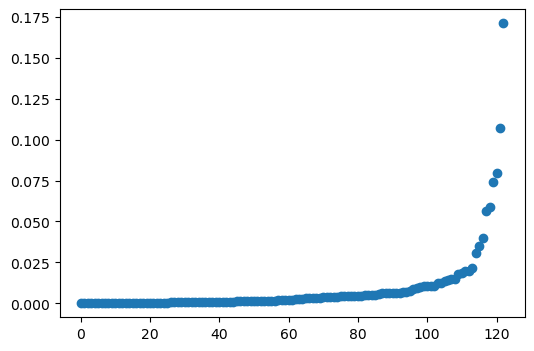

In [7]:
ffhold['cookd'] = ff3modPNC.get_influence().cooks_distance[0]

plt.figure(figsize=[6,4])
plt.scatter(range(len(ffhold['cookd'])),np.sort(ffhold['cookd']))
plt.show()

In [8]:
ffhold.rank(pct=True).sort_values(by='cookd',ascending=False).head(10)

,MktRF,SMB,HML,RF,PNCexret,cookd
Date,,,,,,
2024-02-01,0.967480,0.829268,0.008130,0.504065,0.016260,1.000000
2024-01-22,0.682927,1.000000,0.841463,0.504065,0.243902,0.991870
2024-03-04,0.349593,0.195122,0.747967,0.504065,1.000000,0.983740
2024-02-02,0.869919,0.024390,0.268293,0.504065,0.902439,0.975610
2024-01-03,0.065041,0.016260,0.504065,0.504065,0.024390,0.967480
2024-02-06,0.654472,0.890244,0.300813,0.504065,0.934959,0.959350
2024-03-06,0.731707,0.495935,0.536585,0.504065,0.032520,0.951220
2024-01-08,0.991870,0.906504,0.024390,0.504065,0.731707,0.943089
2024-04-10,0.073171,0.032520,0.060976,0.504065,0.008130,0.934959


\newpage

**Exercise:** Discuss the approach taken above to explore Cook's Distance, and any conclusions drawn from it.

\answerlines{15}

\newpage

**Handling Influential Observations**

Influential observations are almost always an **outlier** in
some sense; this is what causes them to have more influence than
other observations.

First check to see if the influential point is not the
result of a mistake. If so, the
error should be corrected or, if that is not possible, the observation removed. But,
**it is a mistake to arbitrarily remove an observation from a training
set**. Instead, consider the following:

1. One should verify that there truly is a linear
relationship between the response and predictor. A nonlinear model
may be able fit more flexibly to the feature(s) that led to
this outlier.
2. It may be the case that this observation is sufficiently
different from the others that it would make sense to redefine the
population of interest in such a way that this outlying (and other)
cases are handled by a separate model. In other words, it may not be
realistic to expect a single model to cover such a wide range of
possibilities.
3. A transformation of the predictor and/or response can "pull in" an outlier so that it's not so extreme. 
4. An alternative approach to estimating the $\beta_i$ may be preferable; for example, weighted least squares or robust regression.

\newpage

## Power Transformations {-}

We have already seen how transformations of response and/or predictor(s) can help with regression challenges.

Motivated by this, automated procedures for finding optimal transformations have been developed. Here, "optimal" is taken to mean attempting to make the distribution as close as possible to a iid sample from the normal.

**Why normal?** First, predictors with approximately normal distributions will not be skewed and/or have extreme values which tend to be influential points in regression models. Second, if the response can be transformed in such a way to make the residuals approximately normal, then approaches which work best in the case of normality can be utilized, including least squares.

\newpage

**Box-Cox Transformation**

This is **only** useful in the case where the response is **strictly
positive**.

Define Box-Cox **power transformation** function:
\begin{equation*}
   y^{(\lambda)} = \left\{
   \begin{array}{ll}
   \frac{y^{\lambda}-1}{\lambda} & \mbox{if $\lambda \neq 0$} \\
   \log(y) & \mbox{if $\lambda = 0$}
   \end{array}
   \right.
\end{equation*}

This defines a wide range of possible transformations for the response, including
$\sqrt{y}$, $y^2$, $\log(y)$, $1/\sqrt{y}$, and so forth.

**Exercise:** Why is the case $\lambda \neq 0$ defined in the manner it is, instead of just as $y^{\lambda}$?

\answerlines{10}

\newpage

In Python, this is implemented via the function `boxcox()`, which is part of the
package `scipy.stats`.

Let's start with a synthetic example.

In [9]:
x = np.random.gamma(1,4,100)

We note that this is far from a normal shape.

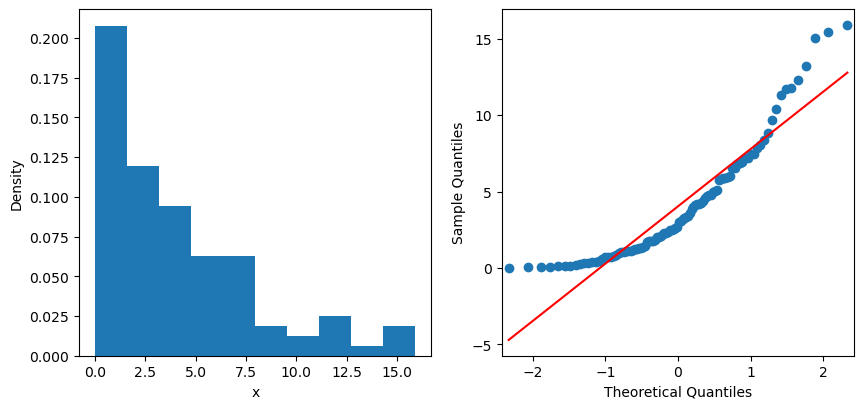

In [10]:
from statsmodels.graphics.gofplots import qqplot

fig, axs = plt.subplots(1, 2, figsize=[10,4.5])
axs[0].hist(x,density=True)
axs[0].set_xlabel("x")
axs[0].set_ylabel("Density")

qqplot(x,line="s",ax=axs[1])
plt.show()

Now we call the `boxcox` function. By specifying `lmbda=None`, we ask the procedure to find the optimal value of $\lambda$ via maximum likelihood. Specifying `alpha=0.05` means that the procedure will return a 95% confidence interval for $\lambda$.

In [11]:
from scipy import stats

xt, lam, CI = stats.boxcox(x, lmbda=None, alpha=0.05)
print(lam)
print(CI)

0.3260480211676779
(0.19511307027528155, 0.46679411054268055)


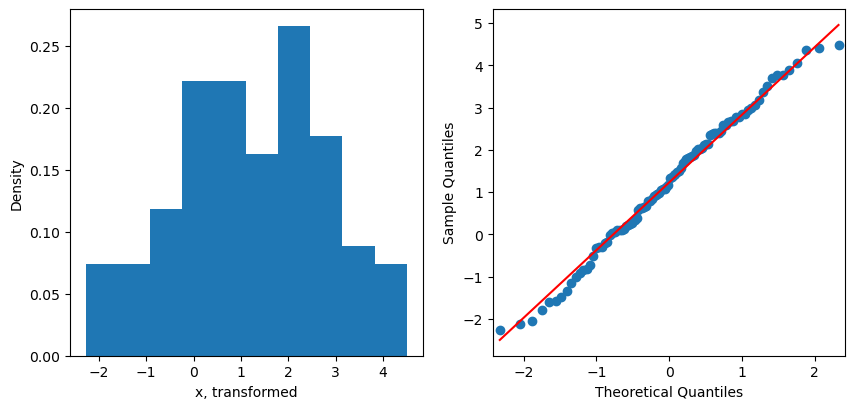

In [12]:
fig, axs = plt.subplots(1, 2, figsize=[10,4.5])
axs[0].hist(xt,density=True)
axs[0].set_xlabel("x, transformed")
axs[0].set_ylabel("Density")

qqplot(xt,line="s",ax=axs[1])
plt.show()

**Comment:** It is standard to choose a "nice" value of $\lambda$ from the 95% confidence interval and use that for the transformation. For example, if 0.5 is in the confidence interval, one would often prefer to use that instead of $\lambda = 0.43$, because the square root transform is easier to interpret. Likewise, if zero is in the interval, the log transform is typically utilized.

\newpage

**Exercise:** Consider the volume data below.

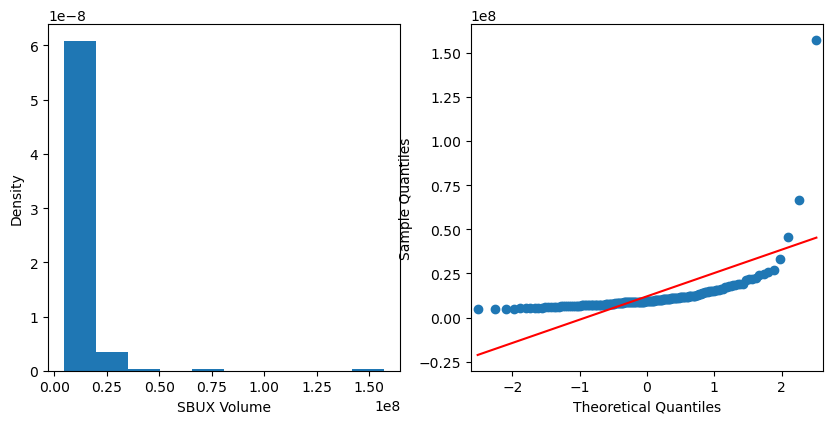

In [13]:
SBUX = yf.Ticker("SBUX").history(start="2024-01-01",end="2024-08-31")

fig, axs = plt.subplots(1, 2, figsize=[10,4.5])
axs[0].hist(SBUX['Volume'],density=True)
axs[0].set_xlabel("SBUX Volume")
axs[0].set_ylabel("Density")

qqplot(SBUX['Volume'],line="s", ax=axs[1])
plt.show()

Try the Box-Cox transformation in this case. What happens?

\answerlines{6}

\newpage

## Box-Cox for Regression {-}

The original motivation for this type of transformation was in the
context of the linear regression model
\begin{equation*}
   Y^{(\lambda)} = \beta_0 + \sum_{j=1}^p \beta_j x_j + \epsilon
\end{equation*}

The question posed by Box and Cox was as follows:
What choice of $\lambda$ yields the best fitting
model, if we want to assume the errors are i.i.d. Normal?

Through a maximum likelihood procedure, the best $\lambda$ can be found,
and then this choice is used to transform the response prior to
fitting the full regression model.

**Exercise:** The Python function `boxcox()` described above operates on a
single vector. How could that be used in the context of this regression
problem?

\answerlines{8}

\newpage

With the help of Gemini, I wrote a function to perform Box-Cox regression, included in this Python notebook.

In [14]:
from scipy.stats import boxcox, chi2

def BoxCoxRegression(X, y, ax=None, alpha=0.05):
    """
    Calculates the optimal Box-Cox transformation parameter lambda for a linear model.
    """
    # Ensure inputs are numpy arrays
    X = np.asarray(X)
    y = np.asarray(y)
    n = len(y)
    
    # Calculate the Hat matrix using the @ operator for matrix multiplication
    # H = X(X^T X)^{-1} X^T
    hat_matrix = X @ np.linalg.inv(X.T @ X) @ X.T
    
    # Pre-compute constants that do not depend on lambda
    sum_log_y = np.sum(np.log(y))
    
    def loglike(lmbda):
        # Transform y
        yt = boxcox(y, lmbda=lmbda)
        
        # Calculate Residual Sum of Squares (RSS)
        # yt_hat = hat_matrix @ yt
        residuals = (hat_matrix @ yt) - yt
        rss = np.sum(residuals**2)
        
        # Log-likelihood formulation
        return -(n / 2.0) * np.log(rss) + lmbda * sum_log_y
        
    # Calculate log-likelihoods over a range of lambda values
    lambda_range = np.linspace(-2, 2, 100)
    log_likes = np.array([loglike(l) for l in lambda_range])
    
    # Optimization and Confidence Intervals
    opt_idx = np.argmax(log_likes)
    lambda_opt = lambda_range[opt_idx]
    max_loglike = log_likes[opt_idx]
    
    # Chi-squared cutoff for confidence interval limits
    conf_lim = max_loglike - chi2.ppf(1 - alpha, 1) / 2.0
    
    # Find the bounds of the interval
    in_interval = lambda_range[log_likes >= conf_lim]
    conf_int = (np.min(in_interval), np.max(in_interval))
    
    # Plotting using native Matplotlib idioms
    if ax is not None:
        y_min = np.min(log_likes)
        
        ax.plot(lambda_range, log_likes, lw=1)
        ax.set_xlabel(r'$\lambda$')
        ax.set_ylabel("Log-Likelihood")
        
        # Use axhline for the horizontal limit line across the whole plot
        ax.axhline(conf_lim, color="red", linestyle="--", lw=0.5)
        
        # Use vlines to draw the three vertical drop-lines efficiently
        ax.vlines(x=[conf_int[0], conf_int[1], lambda_opt], 
                  ymin=y_min, 
                  ymax=[conf_lim, conf_lim, max_loglike], 
                  color="red", linestyle="--", lw=0.5)
        
        # Use f-strings for clean string formatting
        ax.text(conf_int[0], y_min, f"{conf_int[0]:.1f}", ha="center", va="top", size=8)
        ax.text(conf_int[1], y_min, f"{conf_int[1]:.1f}", ha="center", va="top", size=8)
        ax.text(lambda_opt, y_min, f"{lambda_opt:.1f}", ha="center", va="top", size=8)
        
    return lambda_opt, conf_int, lambda_range, log_likes

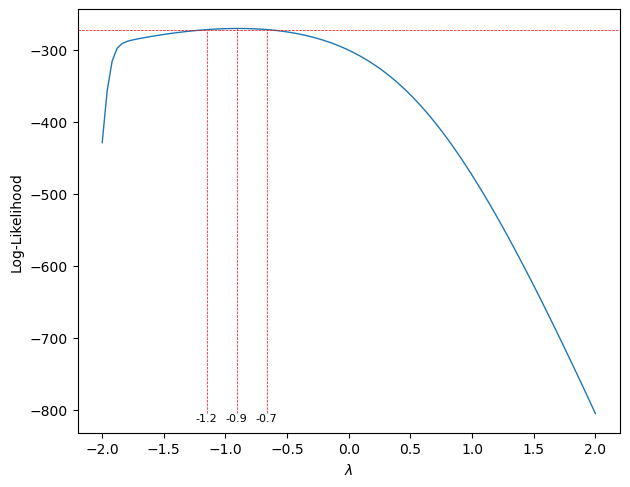

In [15]:
X = np.c_[np.ones(len(SBUX['Close'])),SBUX['Close']]
y = SBUX['Volume']

fig,ax = plt.subplots(1,1,figsize=[7,5.5])
BoxCoxRegression(X,y,ax)
plt.show()

\newpage

**Exercise:** What conclusion do you draw from this analysis?

\answerlines{7}

**Exercise:** Fit the linear model using an appropriate transformation of the response. Assess the results.

\answerlines{10}

\newpage

## The Yeo-Johnson Transformation {-}

The Box-Cox Transformation suffers from the limitation that it can
only be applied to strictly positive variables. A generalization
that works for any variable is the **Yeo-Johnson Transformation**.

The Yeo-Johnson Power Transformation is
\begin{equation*}
   y^{(\lambda,\mbox{\small YJ})} 
   =
   \left\{
   \begin{array}{ll}
   \left(\left(y+1\right)^{\lambda}-1\right)/\lambda, & \mbox{if $\lambda \neq 0, y \geq 0$} \\
   \log\!\left(y + 1\right), & \mbox{if $\lambda = 0, y \geq 0$} \\
   - \left[\left(-y + 1\right)^{2-\lambda} -1  \right]/\left(2-\lambda\right), & \mbox{if $\lambda \neq 2, y < 0$} \\
   - \log\!\left(-y + 1\right),  & \mbox{if $\lambda = 2, y < 0$}
   \end{array}
   \right.
\end{equation*}

It appears somewhat messy, but the intention is much like for the Box-Cox Transformation:
As $\lambda$ varies, we get a wide range of power and log transformations of the data;
the optimal transformation can be sought via maximum likelihood.

In Python this is implemented in `scipy.stats.yeojohnson`.

\newpage

## Example {-}

This brief example will go through the steps commonly seen in a regression analysis, addressing deficiencies in the model fit.

Obtain data on MSFT, from 2016 through 2025.

In [16]:
MSFTdf = yf.Ticker("MSFT").history(start="2016-01-01", end="2025-12-31")

Define the intraday spread as the difference between the high and low price, as a percent of the opening price.

In [17]:
MSFTdf['Spread'] = 100*(MSFTdf['High']-MSFTdf['Low'])/MSFTdf['Open']
MSFTdf.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Spread
Date,,,,,,,,
2016-01-04 00:00:00-05:00,47.263334,47.680977,46.454149,47.680977,53778000,0.0,0.0,2.595729
2016-01-05 00:00:00-05:00,47.794066,48.194307,47.454731,47.898476,34079700,0.0,0.0,1.547421
2016-01-06 00:00:00-05:00,47.263329,47.332938,46.671667,47.028404,39518900,0.0,0.0,1.399120
2016-01-07 00:00:00-05:00,45.853782,46.541154,45.305624,45.392632,56564900,0.0,0.0,2.694501
2016-01-08 00:00:00-05:00,45.566646,46.358429,45.375229,45.531845,48754000,0.0,0.0,2.157719


\newpage

Our objective is to explore models for the relationship between the spread and trading volume.

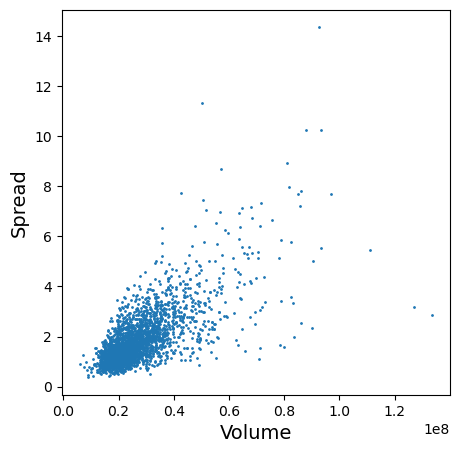

In [18]:
plt.figure(figsize=[5,5])
plt.scatter(MSFTdf['Volume'],MSFTdf['Spread'],s=1)
plt.xlabel("Volume",size=14)
plt.ylabel("Spread",size=14)
plt.show()

\answerlines{5}

\newpage

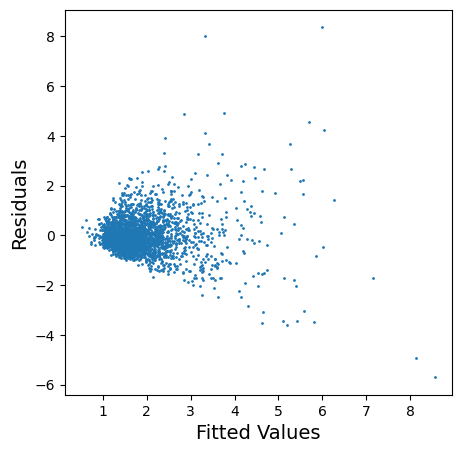

In [19]:
holdlm = sm.OLS.from_formula("Spread~Volume",data=MSFTdf).fit()

plt.figure(figsize=[5,5])
plt.scatter(holdlm.fittedvalues,holdlm.resid,s=1)
plt.xlabel("Fitted Values",size=14)
plt.ylabel("Residuals",size=14)
plt.show()

\answerlines{5}

\newpage

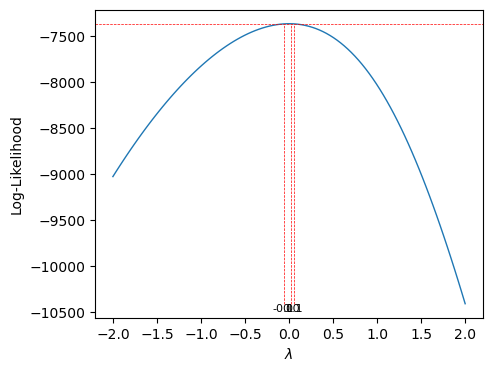

In [20]:
X = np.c_[np.ones(len(MSFTdf['Spread'])),MSFTdf['Volume']]
y = MSFTdf['Spread']

fig,ax = plt.subplots(1,1,figsize=[5,4])
BoxCoxRegression(X,y,ax)
plt.show()

\answerlines{5}

\newpage

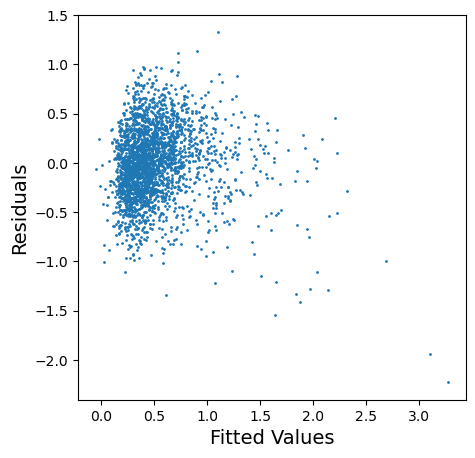

In [21]:
MSFTdf['LogSpread'] = np.log(MSFTdf['Spread'])

holdlm2 = sm.OLS.from_formula(formula="LogSpread~Volume",data=MSFTdf).fit()

plt.figure(figsize=[5,5])
plt.scatter(holdlm2.fittedvalues,holdlm2.resid,s=1)
plt.xlabel("Fitted Values",size=14)
plt.ylabel("Residuals",size=14)
plt.show()

\answerlines{5}

\newpage

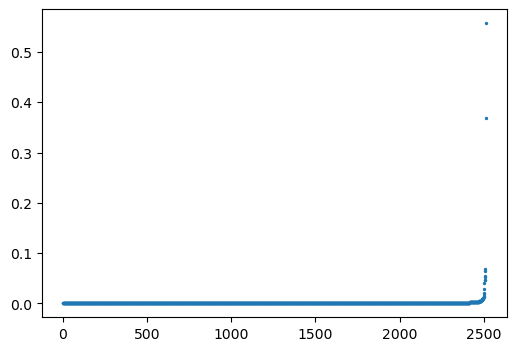

In [22]:
MSFTdf["cookd2"] = holdlm2.get_influence().cooks_distance[0]
plt.figure(figsize=[6,4])
plt.scatter(range(len(MSFTdf['cookd2'])),np.sort(MSFTdf['cookd2']),s=2)
plt.show()

\answerlines{5}

\newpage

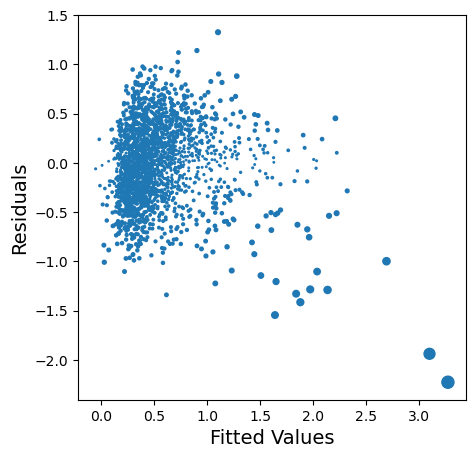

In [23]:
plt.figure(figsize=[5,5])
plt.scatter(holdlm2.fittedvalues,holdlm2.resid,s=(100*np.sqrt(MSFTdf['cookd2'])+1))
plt.xlabel("Fitted Values",size=14)
plt.ylabel("Residuals",size=14)
plt.show()

\answerlines{5}

\newpage

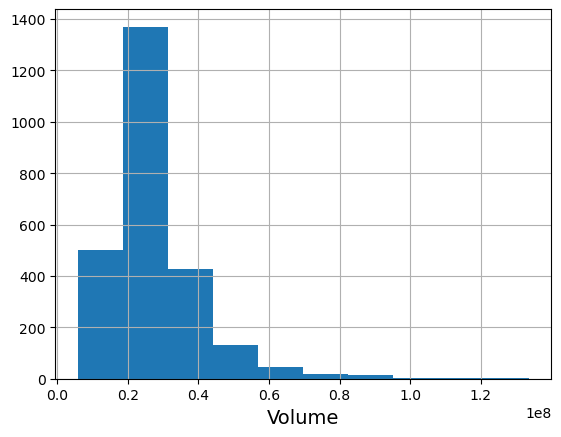

In [24]:
MSFTdf["Volume"].hist()
plt.xlabel("Volume",size=14)
plt.show()

\answerlines{5}

\newpage

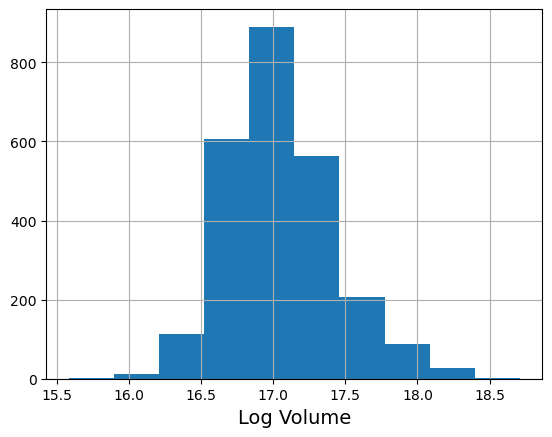

In [25]:
MSFTdf['LogVolume'] = np.log(MSFTdf['Volume'])

MSFTdf["LogVolume"].hist()
plt.xlabel("Log Volume",size=14)
plt.show()

\answerlines{5}

\newpage

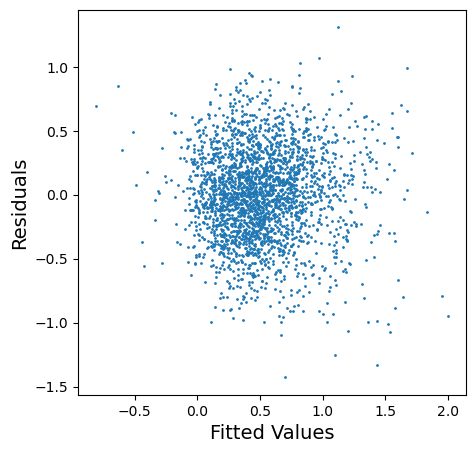

In [26]:
holdlm3 = sm.OLS.from_formula("LogSpread~LogVolume",data=MSFTdf).fit()

plt.figure(figsize=[5,5])
plt.scatter(holdlm3.fittedvalues,holdlm3.resid,s=1)
plt.xlabel("Fitted Values",size=14)
plt.ylabel("Residuals",size=14)
plt.show()

\answerlines{5}

\newpage

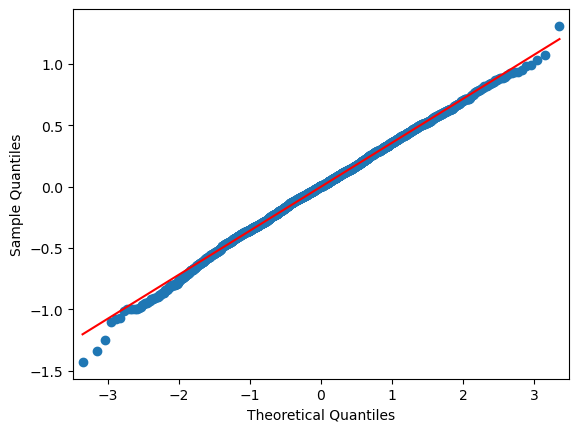

In [27]:
qqplot(holdlm3.resid,line="s")
plt.show()

\answerlines{5}

\newpage

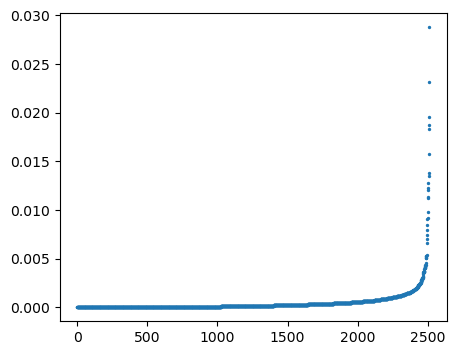

In [28]:
MSFTdf["cookd3"] = holdlm3.get_influence().cooks_distance[0]
plt.figure(figsize=[5,4])
plt.scatter(range(len(MSFTdf['cookd3'])),np.sort(MSFTdf['cookd3']),s=2)
plt.show()

\answerlines{5}

\newpage